In [44]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
import numpy as np
from mytools.utils import get_mask_sector, get_coord, get_mask_square
from crafts_stack.halo_models import (
    get_submodel_contributions,
    get_default_model,
    apply_prior,
)
from crafts_stack.halo_fitting import halofit
from mytools.plot import plot_heatmap, plot_stack_fit_res, compare_profiles, save_plot, plot_sector

%matplotlib inline

# Halo contribution fitting

## stacked result

<Axes: title={'center': 'Masked stack result'}, xlabel='X', ylabel='Y'>

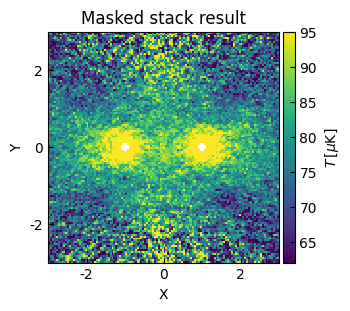

In [46]:
# data = np.load('../data/tng_pairstack_result_cube.npz', 'r')['data']
# stack_result = np.load("../data/tng_pairstack_result_hpmap.npz", "r")["data"]
stack_result = np.load('../data/crafts_pairstack_result_airpls.npz', 'r')['data']

halo_peak_mask = get_mask_sector(rlim=[0.0, 0.1], thetalim=[-np.pi / 2, np.pi / 2])
stack_result_masked = np.ma.array(stack_result, mask=halo_peak_mask, fill_value=0)

plot_heatmap(stack_result_masked, title="Masked stack result", cmap="viridis")

## sector mask

<Axes: title={'center': 'Fitting mask'}, xlabel='X', ylabel='Y'>

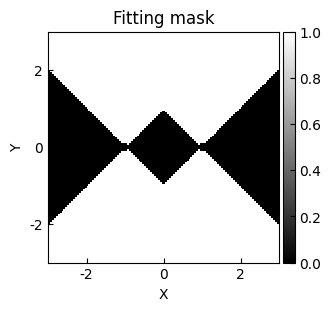

In [47]:
fit_mask = get_mask_sector(rlim=[0.1, 5])
# fit_mask = ~get_mask_square()
plot_heatmap(fit_mask, title="Fitting mask", cmap="gray", cbar_label="")

## analytical model

In [48]:
coord = get_coord()
model = get_default_model()

Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2] + [3] + [4]
Components: 
    [0]: <NFW2D(amplitude=50., x_mean=-1., y_mean=0., r_s=0.5)>

    [1]: <NFW2D(amplitude=50., x_mean=1., y_mean=0., r_s=0.5)>

    [2]: <Gaussian2D(amplitude=50., x_mean=-1., y_mean=0., x_stddev=0.5, y_stddev=0.5, theta=0.)>

    [3]: <Gaussian2D(amplitude=50., x_mean=1., y_mean=0., x_stddev=0.5, y_stddev=0.5, theta=0.)>

    [4]: <Const2D(amplitude=0.)>
Parameters:
    amplitude_0 x_mean_0 y_mean_0 r_s_0 ... y_stddev_3 theta_3 amplitude_4
    ----------- -------- -------- ----- ... ---------- ------- -----------
           50.0     -1.0      0.0   0.5 ...        0.5     0.0         0.0
Fixed parameters are: ['x_mean_0', 'y_mean_0', 'x_mean_1', 'y_mean_1', 'x_mean_2', 'y_mean_2', 'x_mean_3', 'y_mean_3']
Tied parameters are: ['amplitude_0', 'amplitude_2']
Paramters bounds are: [['amplitude_0', (0.0, 100.0)], ['r_s_0', (0.1, None)], ['amplitude_1', (0.0, 100.0)

## analytical fitting

In [49]:
result_list, fitted_model, fit_info = halofit(
    coord, stack_result_masked, model=model, print_model=True, mask=fit_mask
)


Fitted model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2] + [3] + [4]
Components: 
    [0]: <NFW2D(amplitude=1.72944397, x_mean=-1., y_mean=0., r_s=3.72297145)>

    [1]: <NFW2D(amplitude=1.72944397, x_mean=1., y_mean=0., r_s=3.66008501)>

    [2]: <Gaussian2D(amplitude=8.88487595, x_mean=-1., y_mean=0., x_stddev=1.55200917, y_stddev=18.63187738, theta=94.25844684)>

    [3]: <Gaussian2D(amplitude=8.88487595, x_mean=1., y_mean=0., x_stddev=1.67621526, y_stddev=13.88341365, theta=6.24820449)>

    [4]: <Const2D(amplitude=62.90649386)>
Parameters:
       amplitude_0    x_mean_0 y_mean_0 ...      theta_3         amplitude_4    
    ----------------- -------- -------- ... ----------------- ------------------
    1.729443968922456     -1.0      0.0 ... 6.248204492602076 62.906493859437816

Goodness of fit:
Chi-squared: 797631.011
Reduced chi-squared: 77.237
RMS residual: 8.780



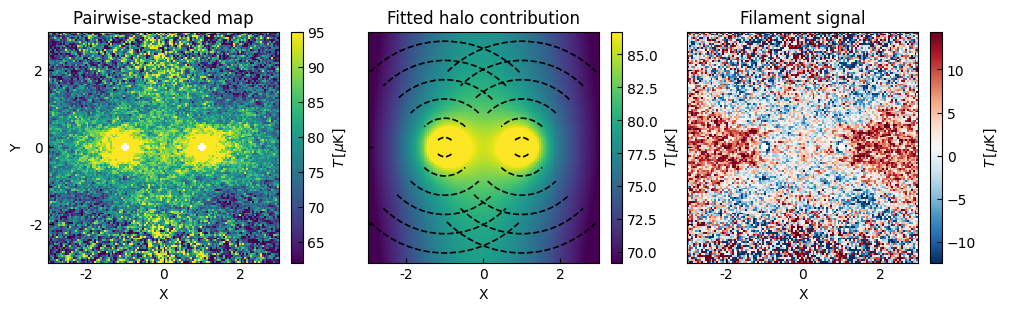

In [102]:
axes = plot_stack_fit_res(
    result_list,  # pyright: ignore[reportArgumentType]
    norm="linear",
    cmap=["viridis", "viridis", "RdBu_r"],
    # vmax=[140,140,10],
    # vmin=[60, 60, -10],
)
fname = "img_tngcube_stack_fit_res_analytical.png"
# save_plot(axes, fname)

plot_sector(axes[1], ec='k')

array([[<Axes: title={'center': 'Y=0'}, ylabel='$T\\,[\\mu$K]'>,
        <Axes: title={'center': 'X=-1'}>,
        <Axes: title={'center': 'X=1'}>],
       [<Axes: ylabel='$\\Delta$$T\\,[\\mu$K]'>, <Axes: >, <Axes: >]],
      dtype=object)

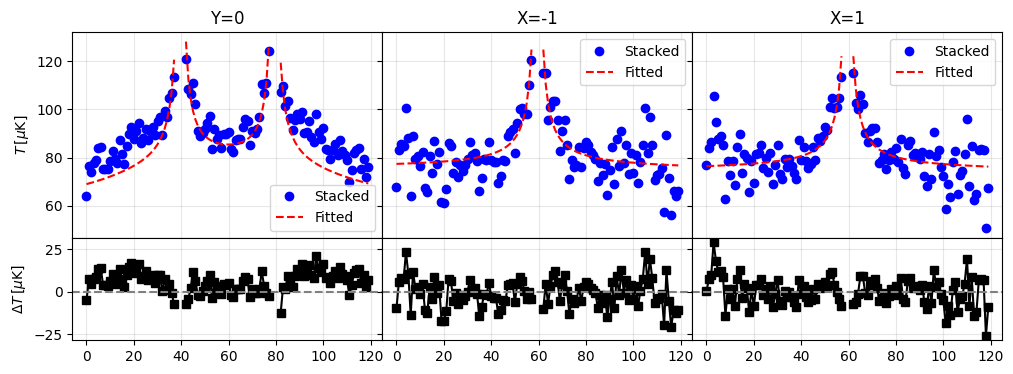

In [51]:
_, fitted, residual = result_list
fitted = np.ma.array(fitted, mask=halo_peak_mask)

compare_profiles([stack_result_masked, fitted])

<Axes: title={'center': 'Normalized Residual'}, xlabel='X', ylabel='Y'>

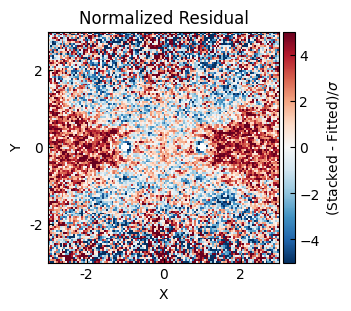

In [52]:
plot_heatmap(
    residual / 2.5,
    title="Normalized Residual",
    cmap="RdBu_r",
    cbar_label=r"(Stacked - Fitted)/$\sigma$",
    vmax=5,
    vmin=-5,
)

In [53]:
bg_mean, bg_std = residual[fit_mask].mean(), residual[fit_mask].std()
bg_mean, bg_std

(np.float64(-7.339395813721733e-05), np.float64(8.77956109434498))

## fitting error

In [69]:
import seaborn as sn
def plot_param_cov(fit_model, fit_info, cmap="viridis", vmin=-1, vmax=1, xticklabels=None, yticklabels=None, *args, **kwargs):
    free_params_index = [not (fit_model.fixed[name] or fit_model.tied[name]) for name in fit_model.param_names]
    free_params = [name for name, index in zip(fit_model.param_names, free_params_index) if index]
    print(free_params)
    cov = fit_info['param_cov']
    if xticklabels is None:
        xticklabels = free_params
    if yticklabels is None:
        yticklabels = free_params
    return sn.heatmap(cov, cmap=cmap, vmin=vmin, vmax=vmax, xticklabels=free_params, yticklabels=free_params, *args, **kwargs)


['r_s_0', 'amplitude_1', 'r_s_1', 'x_stddev_2', 'y_stddev_2', 'theta_2', 'amplitude_3', 'x_stddev_3', 'y_stddev_3', 'theta_3', 'amplitude_4']


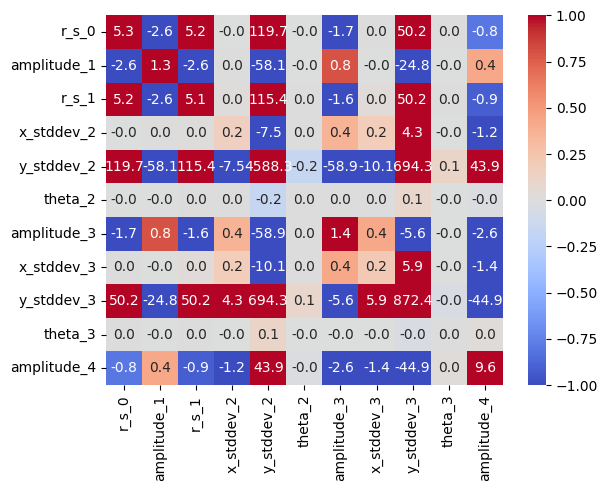

In [70]:
plot_param_cov(fitted_model, fit_info, annot=True, fmt=".1f", cmap='coolwarm');

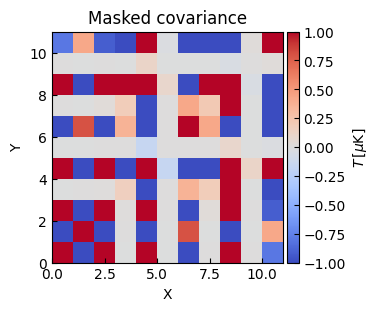

In [92]:
mask_cov = fit_info['param_cov'].copy()
mask_cov[mask_cov<-1] = -1
mask_cov[mask_cov>1] = 1

plot_heatmap(mask_cov, title="Masked covariance", cmap="coolwarm",change_ticks=False);

MC parameter uncertainties from covariance matrix:
  r_s_0: 1.000000 (relative: 26.860%)
  amplitude_1: 1.000000 (relative: 57.822%)
  r_s_1: 1.000000 (relative: 27.322%)
  x_stddev_2: 0.397764 (relative: 25.629%)
  y_stddev_2: 1.000000 (relative: 5.367%)
  theta_2: 0.018995 (relative: 0.020%)
  amplitude_3: 1.000000 (relative: 11.255%)
  x_stddev_3: 0.465404 (relative: 27.765%)
  y_stddev_3: 1.000000 (relative: 7.203%)
  theta_3: 0.019893 (relative: 0.318%)
  amplitude_4: 1.000000 (relative: 1.590%)
MC error map statistics:
  Min: 3.315730
  Max: 80.246424
  Median: 4.386675
  Mean: 4.725504


/home/dyliu/code/crafts_stack/src/crafts_stack/halo_fitting.py:359: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  free_param_samples = rng.multivariate_normal(


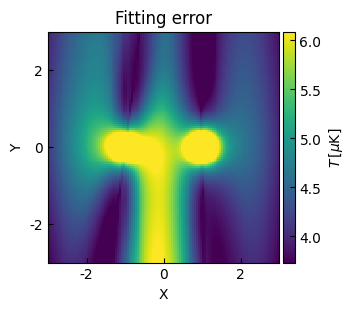

In [93]:
from crafts_stack.halo_fitting import get_fitting_error_bootstrap, get_fitting_error_mc

error_map = get_fitting_error_mc(fitted_model, *coord, cov=mask_cov)
# error_map = get_fitting_error_bootstrap(fitted_model, *coord, stack_result_masked, n_bootstrap=10, use_residuals=False)
plot_heatmap(error_map, title="Fitting error");

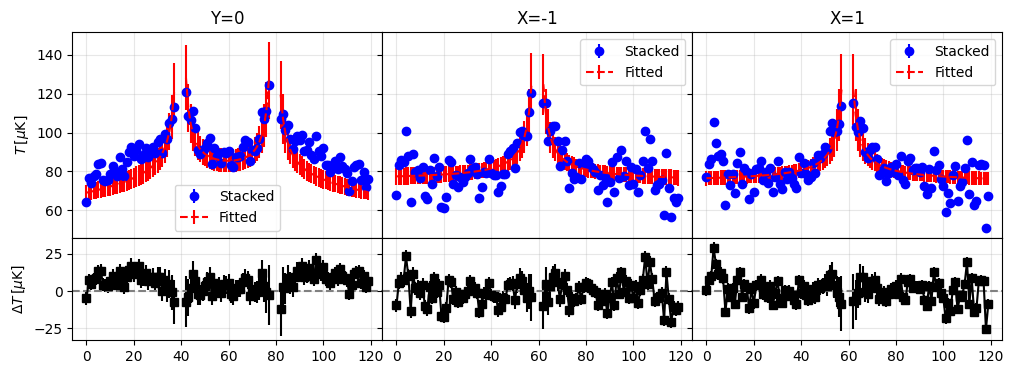

In [94]:
compare_profiles([stack_result_masked, fitted], [np.zeros_like(fitted), error_map]);

# Estimate filament signal level

In [84]:
from mytools.estimate_with_error import get_signal_level
# from mytools.estimate import get_signal_level
from mytools.plot import plot_profile_2c

Parameter names:
('amplitude_0', 'mean_0', 'stddev_0', 'amplitude_1')
Gauss fit parameters: [np.float64(-2.4266793614057205), np.float64(0.0), np.float64(0.5999999999999983), np.float64(2.2527197891445017)]
Gauss fit covariance (without fix mean): 
[[ 0.13338517  0.01396253 -0.01444964]
 [ 0.01396253  0.0116935   0.0081405 ]
 [-0.01444964  0.0081405   0.02210808]]
0 points clipped during sigma clipping.

Goodness of fit:
Chi-squared: 850.347
Reduced chi-squared: 7.268
RMS residual: 2.662

width: 0.5999999999999983
width_pix: 12


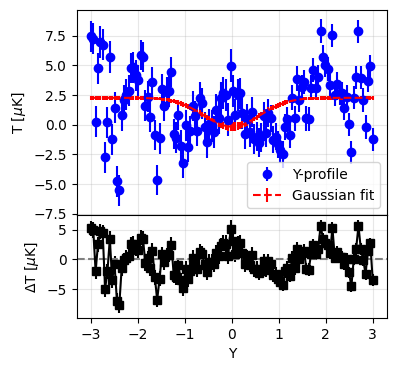

In [85]:
bounds = {
    "amplitude_0": (-np.inf, np.inf),
    "stddev_0": (0, 0.6),
}


lx, ly, ly_error, clrb, clrb_err, params, cov = get_signal_level(
    residual, error_map, bounds=bounds
)

# focus_weight = np.ones_like(fitted)
# focus_weight[:40] = 0
# focus_weight[-40:] = 0
# plot_heatmap(focus_weight, title="Focus weight", cmap="gray")
# lx, ly, clrb, params, cov = get_signal_level(
#     residual, bounds=bounds, weights=focus_weight
# )

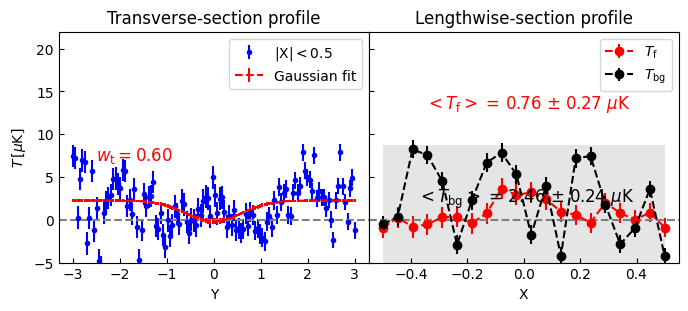

In [86]:
text_pos = [[-0.35, 13], [-0.38, 2], [-2.5, 7]]
axes = plot_profile_2c(lx, ly, width=params[2], y_err=ly_error, text_pos=text_pos)
# axes = plot_profile_2c(lx, ly, width=params[2], text_pos=text_pos)
axes[0].set_ylim(-5, 22)
axes[1].fill_between(
    lx[-1], bg_mean + bg_std, bg_mean - bg_std, facecolor="gray", alpha=0.2
)

# Check submodel contributions

<Axes: title={'center': 'Lorentz contribution'}, xlabel='X', ylabel='Y'>

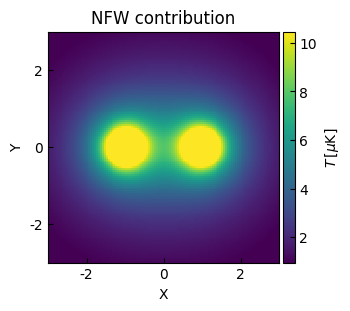

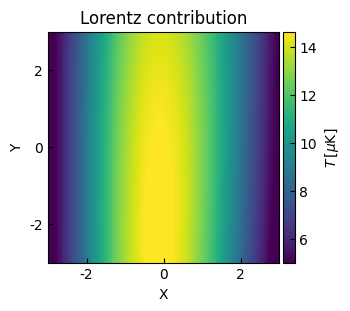

In [87]:
submodel_contris = get_submodel_contributions(fitted_model, *coord)
contris_nfw = submodel_contris[0] + submodel_contris[1]
contris_lorentz = submodel_contris[2] + submodel_contris[3]
contris_bg = submodel_contris[4]
plot_heatmap(contris_nfw, title="NFW contribution", cmap="viridis")
plot_heatmap(contris_lorentz, title="Lorentz contribution", cmap="viridis")

array([[<Axes: title={'center': 'Y=0'}, ylabel='$T\\,[\\mu$K]'>,
        <Axes: title={'center': 'X=-1'}>,
        <Axes: title={'center': 'X=1'}>],
       [<Axes: ylabel='$\\Delta$$T\\,[\\mu$K]'>, <Axes: >, <Axes: >]],
      dtype=object)

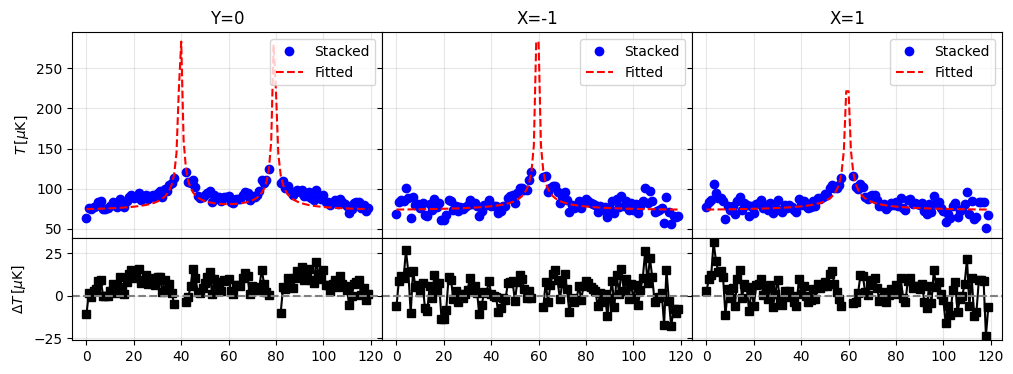

In [88]:
compare_profiles([stack_result_masked, contris_nfw+ contris_bg + 10])

<Axes: title={'center': 'Heatmap'}, xlabel='X', ylabel='Y'>

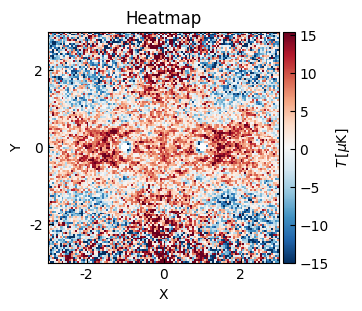

In [89]:
plot_heatmap(stack_result_masked - contris_nfw -contris_bg - 10, cmap='RdBu_r', vmin=-15)